In [ ]:
import numpy as np
import jax.numpy as jnp
import pandas as pd
import matplotlib.pyplot as plt

import importlib
import Hippocampal as HP
import HippocampalJAX as HPJ
importlib.reload(HP)
importlib.reload(HPJ)

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=326890)   # PCG64 by default
cm = 1 / 2.54

# Load Data

In [2]:
n_channels = 31
fs = 1250 # Hz

path = 'data/'
file = 'ec013.527.eeg'
x = np.fromfile(path+file, dtype=np.int16)
x = x.reshape(-1, n_channels)

signal = x[:,5]      # sixth channel
time = np.arange(len(signal))/fs
print(time.shape[0])

1325125


### Plot dense data

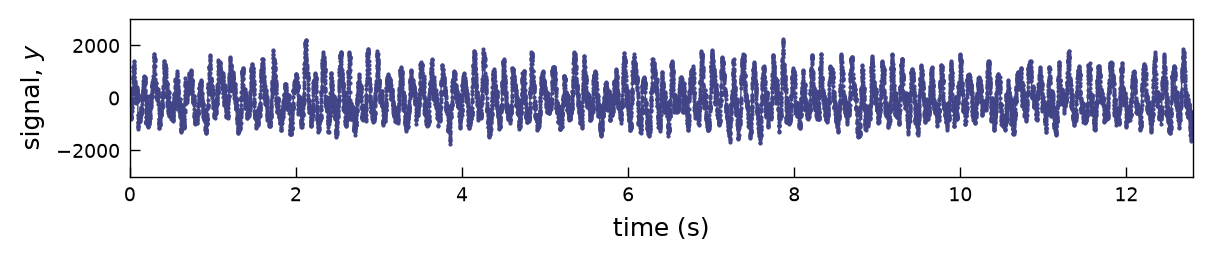

In [3]:
imin = 10000
istep = 1
N = 16000
imax = imin + istep*N

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
dt = np.diff(tk).mean()

# fixed axis geometry
ax_h = 2.0 * cm
ax_w = 13.5 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

ax.plot(tk, yk,  '.-', c=cmap(0.2), lw=0.5, ms=1)
ax.set_xlim(tk[0], tk[-1])
ax.set_ylim(-3000, 3000)

ax.set_xlabel('time (s)', fontsize=9)
ax.set_ylabel('signal, $y$', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

## Effect of added regularizing noise, $R_{\rm add}$

This uses the same spectral-grid JAX workflow as `Hippocampal.ipynb`: raw-data initialization, added-noise fitting data, `R_eff` prior mode tied to `R_add`, and direct JAX Hessian uncertainty by default.

In [4]:
n_theta = 256
M = 3
istep = 4

data = {
    "tk": tk[::istep],
    "yk": yk[::istep],
}

# Sweep from very large regularization toward the operating value used in Hippocampal.ipynb.
R_add_values = np.logspace(7, 4, 15)

# Match the current Hippocampal.ipynb workflow unless intentionally changed.
prior_kwargs = dict(
    sigma_omega=1.0,
    alpha_D=1.0,
    Dtheta_mode=2.0,
    alpha_R=1.0,
)

optimizer_kwargs = dict(
    method="BFGS",
    options=dict(
        maxiter=500, 
        gtol=1e-4,
    ),
)

ppc_kwargs = dict(
    n_param_samples=50,
    n_phase_per_param=2,
    z_tail=1.5,
    alpha=0.05,
)

out = HPJ.sweep_added_noise_jax(
    data,
    R_add_values,
    M=M,
    rng=rng,
    n_theta=n_theta,
    warm_start=False,
    prior_kwargs=prior_kwargs,
    optimizer_kwargs=optimizer_kwargs,
    compute_uncertainty=True,
    hessian_method="direct",
    compute_ppc=True,
    ppc_kwargs=ppc_kwargs,
)

df = out["summary"]

In [5]:
df['success']

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
Name: success, dtype: bool

In [6]:
df

,omega,Dtheta,R_eff,lnDtheta,lnR,M,A0,A1,A2,A3,...,ppc_msd_delta_median,ppc_tail_p,ppc_tail_pass,ppc_tail_delta_mean,ppc_tail_delta_median,ppc_tail_z,ppc_ng_p,ppc_ng_pass,ppc_ng_delta_mean,ppc_ng_delta_median
0,51.862552,2.300882,9.828163e+06,0.833293,16.100763,3,2.536844,1100.632701,88.714947,-0.654052,...,0.240409,0.460784,True,0.004935,0.004141,1.5,0.764706,True,-0.071125,-0.043863
1,51.933707,2.139831,6.294301e+06,0.760727,15.655155,3,-57.594791,928.940080,117.346823,-105.488858,...,0.214928,0.333333,True,0.022743,0.019590,1.5,0.784314,True,-0.044047,-0.035021
2,52.076911,2.254920,3.740331e+06,0.813114,15.134685,3,-17.308284,950.516879,163.790793,36.319515,...,0.624496,0.264706,True,0.032028,0.032375,1.5,0.764706,True,0.061672,0.085127
3,51.856946,2.080148,2.356254e+06,0.732439,14.672584,3,17.893256,870.186929,179.438854,74.958725,...,0.656167,0.333333,True,0.027109,0.024935,1.5,0.784314,True,0.022496,0.053368
4,51.834146,2.202974,1.471408e+06,0.789808,14.201730,3,-27.616439,923.358122,140.252478,69.215318,...,0.326385,0.284314,True,0.033214,0.032011,1.5,0.666667,True,0.054464,0.090041
5,51.816486,1.718562,9.601657e+05,0.541488,13.774861,3,18.214184,927.350363,138.420952,18.487719,...,0.762321,0.274510,True,0.033677,0.033394,1.5,0.588235,True,0.072454,0.082621
6,51.815386,1.956646,6.035606e+05,0.671232,13.310602,3,-4.040015,849.448622,119.159431,38.353501,...,0.456086,0.303922,True,0.022781,0.027214,1.5,0.803922,True,0.024810,0.030855
7,51.862847,2.815522,3.778249e+05,1.035148,12.842186,3,-23.444124,887.590603,174.621830,103.345158,...,-0.262786,0.578431,True,-0.007097,-0.007714,1.5,0.666667,True,0.034252,0.049865
8,51.917275,4.134379,2.416739e+05,1.419337,12.395345,3,-11.620943,918.576295,160.132061,73.751604,...,-0.895351,0.921569,True,-0.042077,-0.038863,1.5,0.647059,True,0.028648,0.044755
9,51.986762,5.897907,1.643318e+05,1.774598,12.009643,3,6.170778,919.663751,133.360729,129.134985,...,-1.199017,0.990196,True,-0.055123,-0.052698,1.5,0.784314,True,0.100138,0.043022


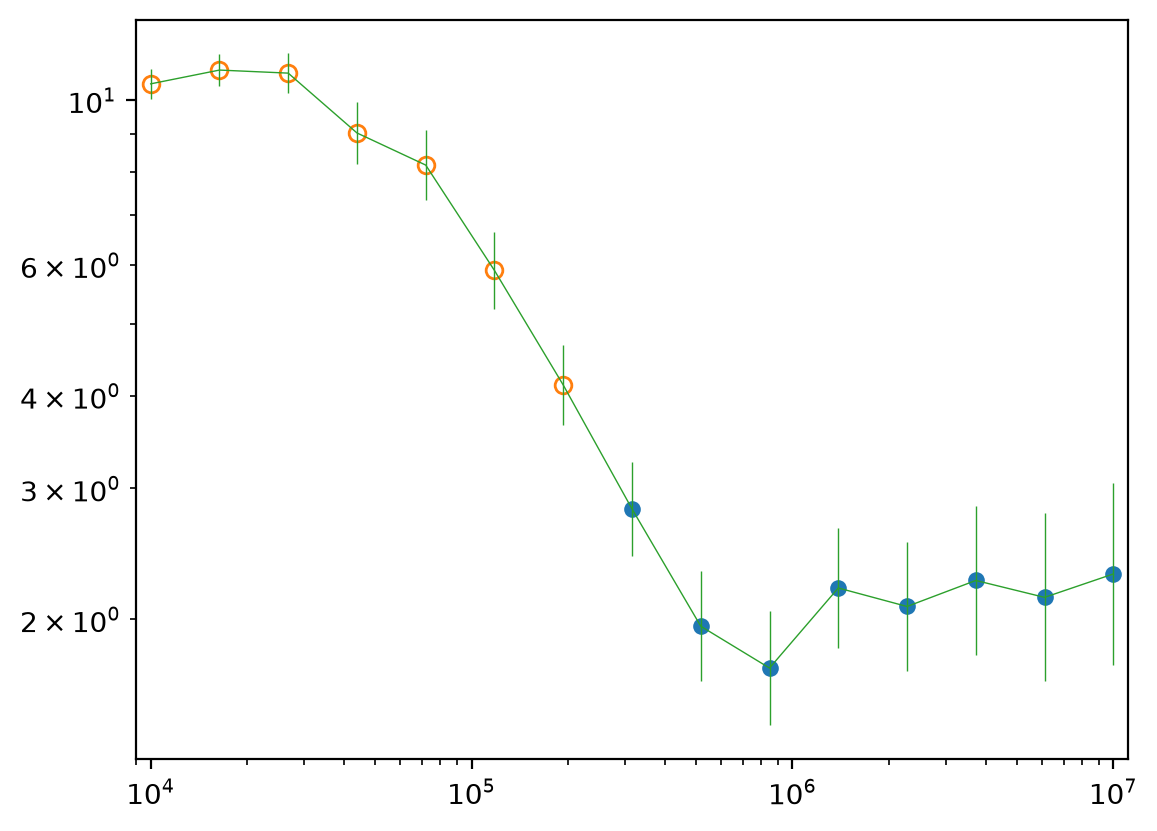

In [7]:
good = (
    df["ppc_tail_pass"]
    & df["ppc_msd_pass"]
    & df["ppc_ng_pass"]
)

plt.loglog(df[good]['R_add'], df[good]['Dtheta'], 'o', mec='None')
plt.loglog(df[~good]['R_add'], df[~good]['Dtheta'], 'o', lw=0.5, mfc='None')
plt.errorbar(
    df["R_add"],
    df["Dtheta"],
    yerr=[
        df["Dtheta"] * (1.0 - np.exp(-df["lnDtheta_se"])),
        df["Dtheta"] * (np.exp(df["lnDtheta_se"]) - 1.0),
    ],
    fmt="-",
    lw=0.5,
)

plt.xlim(0.9*df['R_add'].values.min(), df['R_add'].values.max()/0.9);

## Effect of added regularizing noise and sampling interval, $\Delta t$

In [8]:
dt_configs = [
    dict(label="istep=32", istep=32, N=500),
    dict(label="istep=16", istep=16, N=1000),
    dict(label="istep=8",  istep=8,  N=2000),
    dict(label="istep=4",  istep=4,  N=4000),
]

In [9]:
all_rows = []
all_results = {}

for cfg in dt_configs:
    istep = cfg["istep"]
    N_cfg = cfg["N"]
    imax = imin + istep * N_cfg

    tk_i = time[imin:imax:istep]
    yk_i = signal[imin:imax:istep]

    dt_i = np.diff(tk_i).mean()

    data_i = {
        "tk": tk_i,
        "yk": yk_i,
    }

    out_i = HPJ.sweep_added_noise_jax(
        data_i,
        R_add_values,
        M=M,
        rng=rng,
        n_theta=n_theta,
        warm_start=False,
        prior_kwargs=prior_kwargs,
        optimizer_kwargs=optimizer_kwargs,
        compute_uncertainty=True,
        hessian_method="direct",
        compute_ppc=True,
        ppc_kwargs=ppc_kwargs,
    )

    df_i = out_i["summary"].copy()
    df_i["dt_label"] = cfg["label"]
    df_i["istep"] = istep
    df_i["dt"] = dt_i
    df_i["N_data"] = N_cfg
    df_i["t_min"] = tk_i[0]
    df_i["t_max"] = tk_i[-1]
    df_i["duration"] = tk_i[-1] - tk_i[0]

    all_rows.append(df_i)
    all_results[cfg["label"]] = out_i

df = pd.concat(all_rows, ignore_index=True)

In [10]:
df[df["dt_label"] == "istep=4"].columns

Index(['omega', 'Dtheta', 'R_eff', 'lnDtheta', 'lnR', 'M', 'A0', 'A1', 'A2',
       'A3', 'B0', 'B1', 'B2', 'B3', 'R_add', 'success', 'fun', 'nfev', 'njev',
       'nit', 'message', 'omega_se', 'lnDtheta_se', 'lnR_se', 'Dtheta_mult_se',
       'R_eff_mult_se', 'hessian_method', 'hessian_min_eig', 'hessian_max_eig',
       'hessian_condition', 'rep', 'sweep_index', 'omega_prior_mode', 'R_mode',
       'ppc_tau', 'ppc_lag', 'ppc_msd_p', 'ppc_msd_pass', 'ppc_msd_delta_mean',
       'ppc_msd_delta_median', 'ppc_tail_p', 'ppc_tail_pass',
       'ppc_tail_delta_mean', 'ppc_tail_delta_median', 'ppc_tail_z',
       'ppc_ng_p', 'ppc_ng_pass', 'ppc_ng_delta_mean', 'ppc_ng_delta_median',
       'dt_label', 'istep', 'dt', 'N_data', 't_min', 't_max', 'duration'],
      dtype='str')

### Phase Diffusivity $D_\theta$ vs. $R_\mathrm{add}$ and $\Delta t$

In [11]:
g = df[df["dt_label"] == "istep=16"]

lnDtheta = np.log(g["Dtheta"].to_numpy())
sigma = g["lnDtheta_se"].to_numpy()

w = 1 / sigma**2

lnDtheta_mean = np.sum(w * lnDtheta) / np.sum(w)
lnDtheta_mean_se = 1 / np.sqrt(np.sum(w))

Dtheta_mean = np.exp(lnDtheta_mean)

# asymmetric error bars in linear space
Dtheta_mean_err_lower = Dtheta_mean - np.exp(lnDtheta_mean - lnDtheta_mean_se)
Dtheta_mean_err_upper = np.exp(lnDtheta_mean + lnDtheta_mean_se) - Dtheta_mean

print(Dtheta_mean, Dtheta_mean_err_lower, Dtheta_mean_err_upper)

1.703776949840467 0.08428845188861289 0.0886753574645176


In [12]:
print(np.sqrt(2*Dtheta_mean*32/fs))

0.29535297498388585


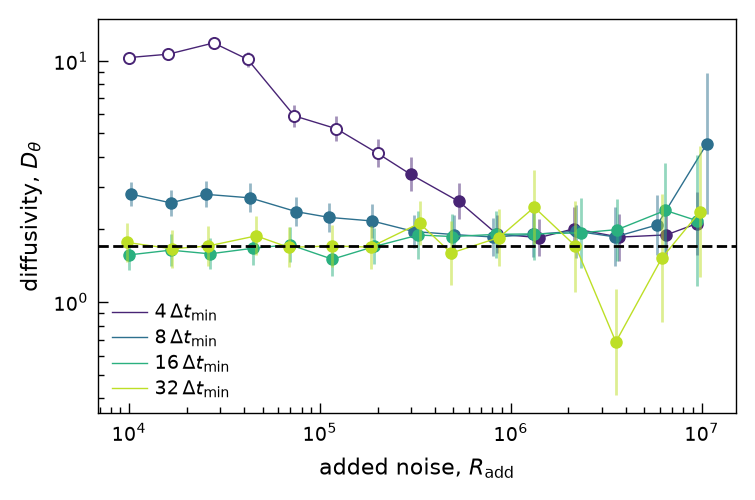

In [13]:
# fixed axis geometry
ax_h = 5 * cm
ax_w = 8.1 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

groups = sorted(
    df.groupby("dt_label"),
    key=lambda x: x[1]["dt"].iloc[0] * fs
)

colors = cmap(np.linspace(0.1, 0.9, len(groups)))

log_jitter = 0.03

ppc_cols = [
    "ppc_tail_pass",
    "ppc_msd_pass",
    "ppc_ng_pass",
]

for color, (label, g) in zip(colors, groups):

    x = g["R_add"].to_numpy()
    xj = x * 10**rng.uniform(-log_jitter, log_jitter, size=len(x))

    D = g["Dtheta"].to_numpy()
    sigma = g["lnDtheta_se"].to_numpy()

    good = g[ppc_cols].all(axis=1).to_numpy()
    bad = ~good

    yerr = np.vstack([
        D - D * np.exp(-sigma),
        D * np.exp(+sigma) - D,
    ])

    ax.errorbar(
        xj, D,
        yerr=yerr,
        fmt="none",
        ecolor=color,
        alpha=0.5,
        elinewidth=1,
        capsize=0,
    )

    factor = int(round(g["dt"].iloc[0] * fs))

    # connecting line only
    ax.plot(
        xj, D,
        "-",
        lw=0.5,
        color=color,
        label=rf"${factor}\,\Delta t_{{\min}}$",
    )

    # good: closed markers
    ax.plot(
        xj[good], D[good],
        "o",
        ms=4,
        mfc=color,
        mec=color,
        mew=0.5,
        linestyle="none",
    )

    # bad: open markers
    ax.plot(
        xj[bad], D[bad],
        "o",
        ms=4,
        mfc="white",
        mec=color,
        mew=0.7,
        linestyle="none",
    )

ax.axhline(y=Dtheta_mean, color='k', lw=1, ls='--')

ax.set_xscale("log")
ax.set_yscale("log")

ax.legend(frameon=False, fontsize=7, loc=3,
          labelspacing=0.3,      # vertical spacing between entries
          handlelength=1.8,      # length of line segment
          handletextpad=0.4,     # gap between symbol and text
          borderpad=0.2,         # padding inside legend box)
          facecolor="white",
          framealpha=0.7,
          edgecolor="none",
         )
    
ax.set_xlabel(r"added noise, $R_{\rm add}$", fontsize=8)
ax.set_ylabel(r"diffusivity, $D_\theta$", fontsize=8)

# tick styling
ax.tick_params(
    axis='both',
    which='major',
    labelsize=7,
    width=0.5,
    direction='in'
)

ax.tick_params(
    axis='both',
    which='minor',
    labelsize=7,
    width=0.5,
    direction='in'
)

# frame styling
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/Diffusivity_vs_Radd_dt.pdf')

### Frequency vs. $R_\mathrm{add}$ and $\Delta t$

In [ ]:
g = df[df["dt_label"] == 'istep=16']

omega = g["omega"].to_numpy()
sigma = g["omega_se"].to_numpy()

w = 1 / sigma**2

omega_mean = np.sum(w * omega) / np.sum(w)
omega_mean_se = 1 / np.sqrt(np.sum(w))

print(omega_mean, omega_mean_se)

51.90299556024595 0.14755171876030623


NameError: name 'omega_mean' is not defined

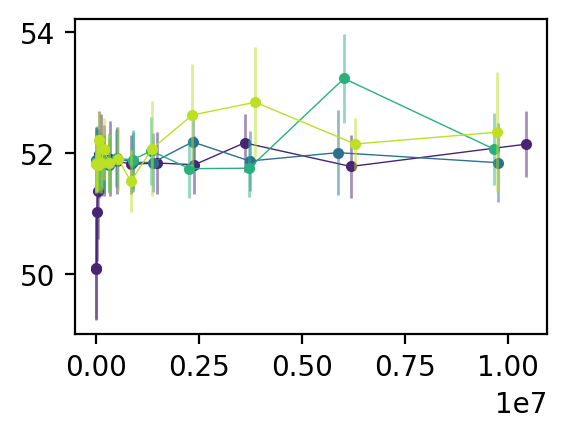

In [ ]:
# fixed axis geometry
ax_h = 4.0 * cm
ax_w = 6.0 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

groups = sorted(
    df.groupby("dt_label"),
    key=lambda x: x[1]["dt"].iloc[0] * fs
)

colors = cmap(np.linspace(0.1, 0.9, len(groups)))
log_jitter = 0.03   # ~7% horizontal spread


for color, (label, g) in zip(colors, groups):
    x = g["R_add"].to_numpy()
    xj = x * 10**rng.uniform(-log_jitter, log_jitter, size=len(x))

    ax.errorbar(
        xj,
        g["omega"],
        yerr=g["omega_se"],
        fmt="none",
        ecolor=color,
        alpha=0.5,
        elinewidth=1,
        capsize=0,
    )

    factor = int(round(g["dt"].iloc[0] * fs))

    ax.plot(
        xj,
        g["omega"],
        "o-",
        # mew = 0.5,
        # mfc = 'None',
        # ms = 5,
        ms = 4,
        mew = 0,
        lw = 0.5,
        color = color,
        label=rf"${factor}\,\Delta t_{{\min}}$",
    )

ax.axhline(y=omega_mean, color='k', lw=1,ls='--')

ax.set_xscale("log")

ax.legend(frameon=False, fontsize=7, loc=4,
          labelspacing=0.3,      # vertical spacing between entries
          handlelength=1.8,      # length of line segment
          handletextpad=0.4,     # gap between symbol and text
          borderpad=0.2,         # padding inside legend box)
          facecolor="white",
          framealpha=0.7,
          edgecolor="none",
         )

ax.set_xlabel(r"added noise, $R_{\rm add}$", fontsize=9)
ax.set_ylabel(r"frequency, $\omega$", fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)